# Laboratorio 2 · PennyLane: kernels, clustering y regresión
**Workshop de computación cuántica · SCAYLE · Bloque 3: Quantum Machine Learning**

En el Laboratorio 1 las clases de Qiskit hacían el trabajo por nosotros. Aquí bajamos un nivel y **escribimos los circuitos a mano** con PennyLane:

1. **El kernel cuántico desde cero**, comprobando que es *exactamente* el mismo que el `zz_feature_map` de Qiskit.
2. **Clasificación**: el kernel cuántico dentro de una SVM de scikit-learn.
3. **Clustering**: el *mismo* kernel, ahora sin etiquetas.
4. **Regresión**: un modelo de **1 qubit** con *data re-uploading* entrenado con gradientes.

**Duración:** unos 10 minutos. Ejecuta las celdas **en orden**.

## 0. Importaciones y comprobación del entorno

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import pennylane as qml
from pennylane import numpy as pnp          # NumPy de PennyLane: permite calcular gradientes
import sklearn

from sklearn.datasets import make_moons
from sklearn.cluster import SpectralClustering
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC, SVR

SEMILLA = 42
N_QUBITS = 2
dev = qml.device("default.qubit", wires=N_QUBITS)    # simulador exacto de PennyLane

print(f"pennylane {qml.__version__} · scikit-learn {sklearn.__version__} · numpy {np.__version__}")

pennylane 0.45.1 · scikit-learn 1.9.1 · numpy 2.5.3


## 1. El kernel cuántico, escrito a mano
Reproducimos el feature map ZZ de Qiskit con **una** repetición:

* `Hadamard` en cada qubit;
* `RZ(2·xᵢ)` en cada qubit. En Qiskit se usa la puerta de fase `P(2·xᵢ)`, pero solo difiere de `RZ` en una **fase global**, que no cambia ninguna probabilidad;
* `CNOT` – `RZ(2·(π−x₀)(π−x₁))` – `CNOT`: la interacción ZZ que **entrelaza** los qubits según los datos.

**El truco del kernel:** para medir el solapamiento entre $|\varphi(x_1)\rangle$ y $|\varphi(x_2)\rangle$ se aplica el feature map de $x_1$ y después su **inverso** (`qml.adjoint`) con $x_2$. Si los estados son iguales, se vuelve a $|00\rangle$. Por eso

$$k(x_1, x_2) = P(\text{medir } |00\rangle) = |\langle\varphi(x_2)|\varphi(x_1)\rangle|^2 .$$

In [2]:
def feature_map(x):
    """Equivalente a zz_feature_map(2, reps=1) de Qiskit (Havlíček et al., 2019)."""
    for i in range(N_QUBITS):
        qml.Hadamard(wires=i)
        qml.RZ(2 * x[i], wires=i)                            # = P(2x) salvo una fase global
    qml.CNOT(wires=[0, 1])
    qml.RZ(2 * (np.pi - x[0]) * (np.pi - x[1]), wires=1)     # interacción ZZ
    qml.CNOT(wires=[0, 1])

@qml.qnode(dev)
def circuito_kernel(x1, x2):
    feature_map(x1)
    qml.adjoint(feature_map)(x2)
    return qml.probs(wires=range(N_QUBITS))                 # [P(00), P(01), P(10), P(11)]

def qkernel(A, B):
    """Matriz de kernel: k(a, b) = probabilidad de medir |00>."""
    return np.array([[circuito_kernel(a, b)[0] for b in B] for a in A])

print(qml.draw(circuito_kernel)([0.3, 1.2], [0.5, 2.0]))

0: ──H──RZ(0.60)─╭●────────────╭●─╭X†────────────╭X†──RZ(1.00)†──H†─┤ ╭Probs
1: ──H──RZ(2.40)─╰X──RZ(11.03)─╰X─╰X†──RZ(6.03)†─╰X†──RZ(4.00)†──H†─┤ ╰Probs


### 1.1 Comprobaciones de sentido común
Antes de usar el kernel verificamos tres propiedades. Si alguna fallara, habría un error en el circuito:

1. $k(x, x) = 1$: un estado coincide consigo mismo.
2. $k(x_1, x_2) = k(x_2, x_1)$: el kernel es simétrico.
3. Coincide con el kernel de **Qiskit** con `zz_feature_map(2, reps=1)` (un cálculo independiente).

In [3]:
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

puntos = np.random.default_rng(0).uniform(0, np.pi, size=(6, 2))   # puntos de prueba (no afectan a los resultados)
K_pl = qkernel(puntos, puntos)
K_qk = FidelityStatevectorKernel(feature_map=zz_feature_map(2, reps=1)).evaluate(puntos)

print("1) Diagonal = 1:          ", np.allclose(np.diag(K_pl), 1))
print("2) Simétrico:             ", np.allclose(K_pl, K_pl.T))
print("3) Igual que Qiskit:      ", np.allclose(K_pl, K_qk), f"(diferencia máxima {np.abs(K_pl - K_qk).max():.1e})")

1) Diagonal = 1:           True
2) Simétrico:              True
3) Igual que Qiskit:       True (diferencia máxima 8.9e-16)


## 2. Datos: las dos lunas
Un dataset sintético clásico de scikit-learn: dos medias lunas entrelazadas con algo de ruido. **No es separable con una línea recta**, así que obliga a usar un kernel no lineal. Escalamos a $[0, \pi]$ (ángulos) y separamos 70 puntos de entrenamiento y 30 de test.

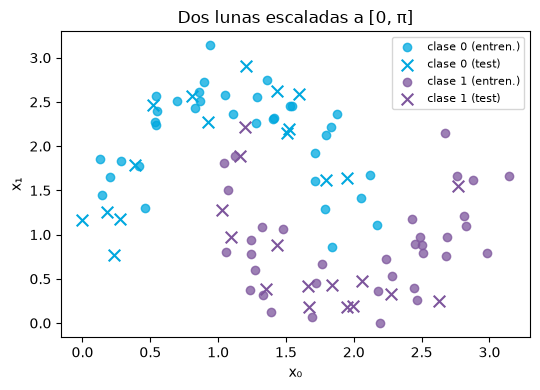

In [4]:
X, y = make_moons(n_samples=100, noise=0.15, random_state=SEMILLA)
X = MinMaxScaler((0, np.pi)).fit_transform(X)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, train_size=0.7, stratify=y, random_state=SEMILLA)

fig, ax = plt.subplots(figsize=(5.5, 4))
for c, col in [(0, "#00A8DF"), (1, "#7D559C")]:
    ax.scatter(*X_tr[y_tr == c].T, c=col, alpha=0.75, label=f"clase {c} (entren.)")
    ax.scatter(*X_te[y_te == c].T, c=col, marker="x", s=70, label=f"clase {c} (test)")
ax.set_xlabel("x₀"); ax.set_ylabel("x₁"); ax.set_title("Dos lunas escaladas a [0, π]"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Clasificación: SVM con kernel RBF vs. SVM con kernel cuántico
scikit-learn acepta un kernel ya calculado con `kernel="precomputed"`. Necesita dos matrices:

* `K_tr` (70 × 70): similitudes **entre** los puntos de entrenamiento → para entrenar.
* `K_te` (30 × 70): similitud de cada punto de test **con** cada punto de entrenamiento → para predecir.

Calcularlas son 7.000 ejecuciones del circuito: tarda **unos 15 segundos**.

In [5]:
print("== Clasificación (dos lunas) ==")
svc = SVC(kernel="rbf").fit(X_tr, y_tr)
print(f"SVC RBF           test={svc.score(X_te, y_te):.2f}")

t = time.time()
K_tr = qkernel(X_tr, X_tr)
K_te = qkernel(X_te, X_tr)
qsvc = SVC(kernel="precomputed").fit(K_tr, y_tr)
print(f"SVC kernel cuánt. test={qsvc.score(K_te, y_te):.2f}  tiempo kernel={time.time()-t:.1f}s")

== Clasificación (dos lunas) ==
SVC RBF           test=0.93


SVC kernel cuánt. test=0.77  tiempo kernel=12.6s


### 3.1 ¿Dónde pone la frontera cada modelo?
Evaluamos ambos clasificadores en una rejilla de 15 × 15 puntos. Para el kernel cuántico eso son 225 × 70 ≈ 16.000 circuitos: tarda **unos 30 segundos**.

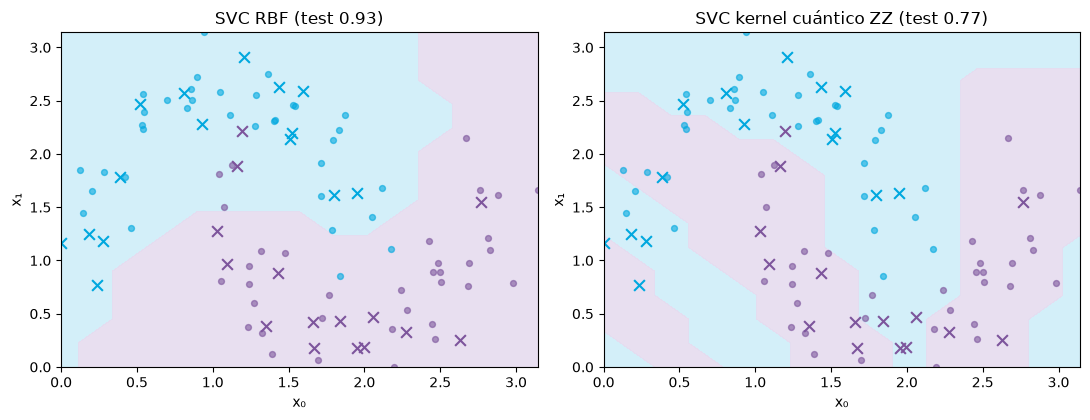

In [6]:
g = np.linspace(0, np.pi, 15)
G = np.array([[a, b] for b in g for a in g])
z_rbf = svc.predict(G).reshape(15, 15)
z_q = qsvc.predict(qkernel(G, X_tr)).reshape(15, 15)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, z, titulo in [(axes[0], z_rbf, f"SVC RBF (test {svc.score(X_te, y_te):.2f})"),
                      (axes[1], z_q, f"SVC kernel cuántico ZZ (test {qsvc.score(K_te, y_te):.2f})")]:
    ax.contourf(g, g, z, levels=[-0.5, 0.5, 1.5], colors=["#cfeef9", "#e6dcef"], alpha=0.9)
    for c, col in [(0, "#00A8DF"), (1, "#7D559C")]:
        ax.scatter(*X_tr[y_tr == c].T, c=col, s=18, alpha=0.6)
        ax.scatter(*X_te[y_te == c].T, c=col, marker="x", s=60)
    ax.set_title(titulo); ax.set_xlabel("x₀"); ax.set_ylabel("x₁")
plt.tight_layout(); plt.show()

> **Observa:** las dos fronteras son distintas porque cada kernel define «parecido» de una manera diferente. El RBF depende solo de la distancia euclídea, y su frontera sigue la forma de las lunas. El kernel ZZ combina fases periódicas de los datos ($2x_i$) con el término producto $(\pi-x_0)(\pi-x_1)$: su frontera forma **franjas** que no siguen la geometría de las lunas, y por eso falla más puntos de test.

## 4. Clustering con el mismo kernel (sin etiquetas)
El *clustering espectral* agrupa puntos a partir de una **matriz de afinidad** (de similitudes). Le pasamos el kernel cuántico **sin modificar** y medimos el acuerdo con las etiquetas reales con el **índice de Rand ajustado (ARI)**:

* ARI = 1: coincidencia perfecta;
* ARI ≈ 0: no mejor que el azar.

Las etiquetas `y` **no** se usan para agrupar; solo para evaluar al final.

== Clustering (dos lunas, no supervisado) ==


Espectral RBF            ARI=0.54
Espectral kernel cuánt.  ARI=0.46


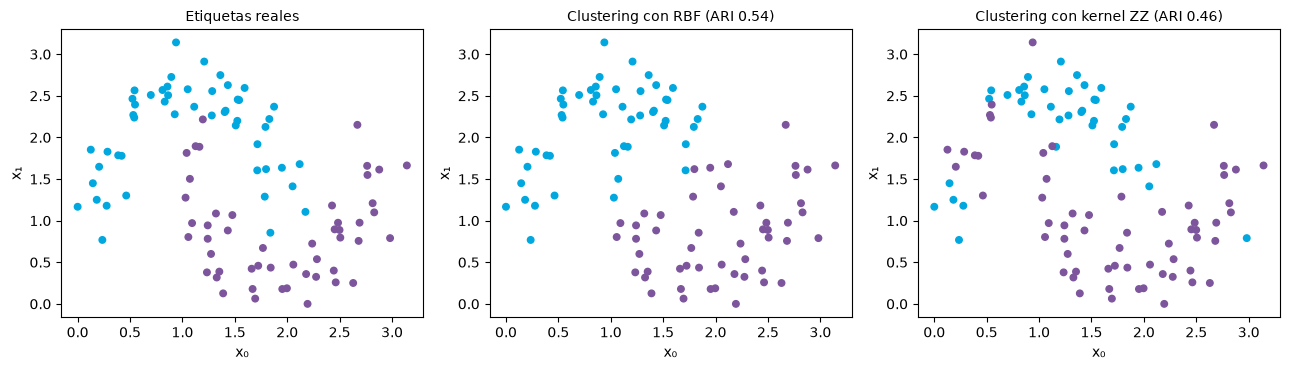

In [7]:
print("== Clustering (dos lunas, no supervisado) ==")
K_all = qkernel(X, X)
lab_q = SpectralClustering(2, affinity="precomputed", random_state=SEMILLA).fit_predict(K_all)
lab_c = SpectralClustering(2, affinity="precomputed", random_state=SEMILLA).fit_predict(rbf_kernel(X, gamma=1.0))
print(f"Espectral RBF            ARI={adjusted_rand_score(y, lab_c):.2f}")
print(f"Espectral kernel cuánt.  ARI={adjusted_rand_score(y, lab_q):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, etiquetas, titulo in [(axes[0], y, "Etiquetas reales"),
                              (axes[1], lab_c, f"Clustering con RBF (ARI {adjusted_rand_score(y, lab_c):.2f})"),
                              (axes[2], lab_q, f"Clustering con kernel ZZ (ARI {adjusted_rand_score(y, lab_q):.2f})")]:
    ax.scatter(*X.T, c=np.where(etiquetas == 0, "#00A8DF", "#7D559C"), s=22)
    ax.set_title(titulo, fontsize=10); ax.set_xlabel("x₀"); ax.set_ylabel("x₁")
plt.tight_layout(); plt.show()

> **Nota:** los números de los grupos (0 o 1) que asigna el clustering son arbitrarios, así que los colores pueden salir intercambiados respecto a las etiquetas reales. El ARI no se ve afectado por ese intercambio.

## 5. Regresión con 1 qubit: *data re-uploading*
Objetivo: aprender $f(x) = \sin(x)$ (variable `FREC = 1`) en $[-\pi, \pi]$ con un circuito de **un solo qubit**. El truco es **volver a cargar el dato** varias veces, intercalado con rotaciones entrenables:

$$\text{capa}_\ell:\quad R_X(x)\;\rightarrow\;\text{Rot}(w_{\ell,0}, w_{\ell,1}, w_{\ell,2}), \qquad \ell = 1, 2, 3$$

La salida es el valor esperado $\langle Z\rangle \in [-1, 1]$, el mismo rango que $\sin(x)$. Con 3 capas hay **9 parámetros**.

In [8]:
dev1 = qml.device("default.qubit", wires=1)
CAPAS = 3      # nº de veces que se carga el dato (reto 2: prueba 5)
FREC = 1       # función objetivo sin(FREC·x)  (reto 2: prueba 5)

@qml.qnode(dev1)
def modelo(x, w):
    for l in range(CAPAS):
        qml.RX(x, wires=0)                                   # se vuelve a cargar la entrada
        qml.Rot(w[l, 0], w[l, 1], w[l, 2], wires=0)          # rotación entrenable
    return qml.expval(qml.PauliZ(0))                         # salida en [-1, 1]

# Generador con semilla propia: si vuelves a ejecutar esta celda obtienes los mismos datos
# y el mismo punto inicial (y los mismos números que el script del laboratorio)
gen = np.random.default_rng(SEMILLA)
x_tr = np.linspace(-np.pi, np.pi, 30); y_tr_r = np.sin(FREC * x_tr)
x_te = gen.uniform(-np.pi, np.pi, 20);  y_te_r = np.sin(FREC * x_te)
w_inicial = gen.normal(0, 0.5, (CAPAS, 3))

def mse(w, xs, ys):
    return sum((modelo(x, w) - yv) ** 2 for x, yv in zip(xs, ys)) / len(xs)

print(qml.draw(modelo)(0.5, np.zeros((CAPAS, 3))))

0: ──RX(0.50)──Rot(0.00,0.00,0.00)──RX(0.50)──Rot(0.00,0.00,0.00)──RX(0.50)──Rot(0.00,0.00,0.00)─┤ ···

0: ···   <Z>


### 5.1 ¿Qué funciones puede representar este circuito?
Con $L$ capas, la salida es una **serie de Fourier** en $x$ con frecuencias enteras de 0 a $L$ (Schuld, Sweke y Meyer, 2021). PennyLane lo calcula directamente: marcamos la puerta que codifica $x$ y pedimos su espectro.

In [9]:
@qml.qnode(dev1)
def modelo_marcado(x, w):
    for l in range(CAPAS):
        qml.fourier.mark(qml.RX(x, wires=0), "x")           # marcamos la puerta que codifica x
        qml.Rot(w[l, 0], w[l, 1], w[l, 2], wires=0)
    return qml.expval(qml.PauliZ(0))

espectro = qml.fourier.circuit_spectrum(modelo_marcado, encoding_gates=["x"])(0.5, np.zeros((CAPAS, 3)))
frecuencias = sorted(int(f) for f in espectro["x"] if f >= 0)
print(f"Frecuencias accesibles con {CAPAS} capas:", frecuencias)
if FREC in frecuencias:
    print(f"sin({FREC}·x) tiene frecuencia {FREC}  →  está dentro del espectro: el modelo PUEDE representarla.")
else:
    print(f"sin({FREC}·x) tiene frecuencia {FREC}  →  NO está en el espectro: el modelo NO puede representarla.")

Frecuencias accesibles con 3 capas: [0, 1, 2, 3]
sin(1·x) tiene frecuencia 1  →  está dentro del espectro: el modelo PUEDE representarla.


### 5.2 Entrenamiento con gradientes (Adam)
PennyLane calcula los gradientes de $\langle Z\rangle$ respecto a $w$ de forma automática (en hardware usaría la *regla de desplazamiento de parámetros*). Entrenamos 60 épocas con Adam (tasa de aprendizaje 0,1): tarda **unos 15 segundos**.

In [10]:
print(f"== Regresión  f(x)=sin({FREC}·x) en [-pi, pi] ==")
w = pnp.array(w_inicial, requires_grad=True)
opt = qml.AdamOptimizer(stepsize=0.1)
historial = []
t = time.time()
for epoca in range(60):
    w = opt.step(lambda v: mse(v, x_tr, y_tr_r), w)
    historial.append(float(mse(w, x_tr, y_tr_r)))
    if epoca % 20 == 0 or epoca == 59:
        print(f"época {epoca:2d}  MSE entren.={historial[-1]:.4f}")
print(f"VQR  MSE test={mse(w, x_te, y_te_r):.4f}  tiempo={time.time()-t:.1f}s  parámetros={w.size}")

svr = SVR(kernel="rbf").fit(x_tr.reshape(-1, 1), y_tr_r)
print(f"SVR RBF  MSE test={np.mean((svr.predict(x_te.reshape(-1, 1)) - y_te_r)**2):.4f}")

== Regresión  f(x)=sin(1·x) en [-pi, pi] ==
época  0  MSE entren.=1.0211


época 20  MSE entren.=0.0220


época 40  MSE entren.=0.0032


época 59  MSE entren.=0.0002
VQR  MSE test=0.0002  tiempo=16.5s  parámetros=9
SVR RBF  MSE test=0.0055


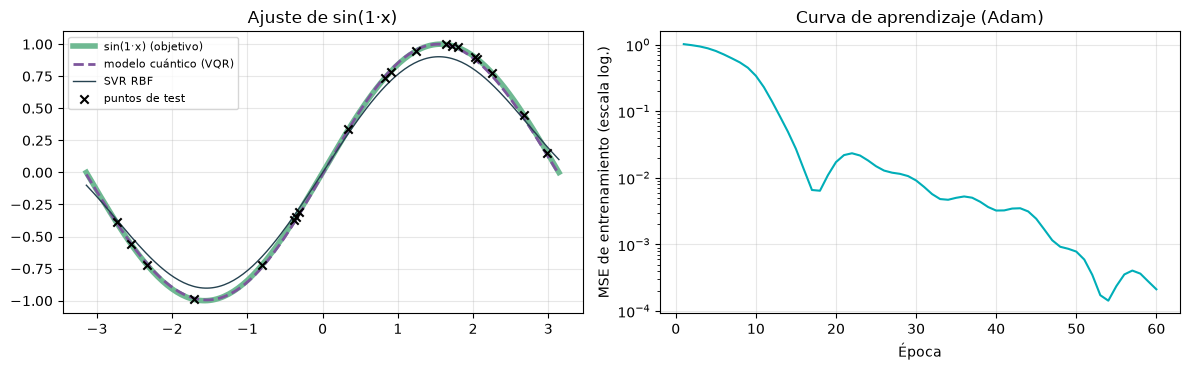

In [11]:
xs = np.linspace(-np.pi, np.pi, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(xs, np.sin(FREC * xs), color="#6FB992", lw=4, label=f"sin({FREC}·x) (objetivo)")
axes[0].plot(xs, [float(modelo(x, w)) for x in xs], color="#7D559C", ls="--", lw=2, label="modelo cuántico (VQR)")
axes[0].plot(xs, svr.predict(xs.reshape(-1, 1)), color="#254250", lw=1, label="SVR RBF")
axes[0].scatter(x_te, y_te_r, c="black", marker="x", label="puntos de test", zorder=3)
axes[0].set_title(f"Ajuste de sin({FREC}·x)"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].semilogy(range(1, 61), historial, color="#00AEB8")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("MSE de entrenamiento (escala log.)")
axes[1].set_title("Curva de aprendizaje (Adam)"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

> **¡Ojo con el entusiasmo!** El modelo cuántico ajusta casi perfectamente, pero la tarea está hecha a su medida: $\sin(x)$ es **una única frecuencia** de Fourier, justo lo que este circuito representa mejor. Una comparación justa necesitaría tareas que no se elijan pensando en el modelo. En el reto 4 lo comprobarás con $\sin(5x)$.

## 6. Conclusiones
* Un **kernel cuántico** es solo una función de similitud: la misma matriz sirve para clasificar (SVC) y para agrupar (clustering espectral). La parte cuántica se limita a calcular la matriz.
* El kernel ZZ **no supera** al RBF en las dos lunas: empata o pierde según la tarea. Su calidad depende de que la codificación encaje con la geometría de los datos.
* En regresión, el **diseño del circuito** (cuántas veces se carga el dato) fija qué funciones puede aprender: es su **sesgo inductivo**.
* Escribir los circuitos a mano y **comprobarlos** frente a una implementación independiente (aquí, Qiskit) es una buena práctica de ingeniería.

## 7. Retos (para los minutos finales o para casa)
1. **Entrelazamiento:** en la celda de la Sección 1 comenta las dos `CNOT` y la `RZ` de la interacción ZZ, ejecútala y vuelve a ejecutar desde la Sección 3. ¿Mejora o empeora? Pista: compara con Bowles, Ahmed y Schuld (2024). *(Si repites la Sección 1.1, la comprobación 3 dará `False`: es lo esperado, porque ya no es el mapa ZZ de Qiskit.)*
2. **Sesgo inductivo:** en la Sección 5 pon `FREC = 5` y ejecuta desde ahí. ¿Por qué falla con `CAPAS = 3`? Prueba después con `CAPAS = 5`. El mensaje del espectro de la Sección 5.1 te da la pista.

*Apunta cada cambio y su resultado, como en cualquier registro de experimentos de ML.*